# Mushroom Edibility Classification

### An end-to-end machine-learning project for classifying mushrooms as edible or poisonous

## About this project

This notebook builds a reproducible binary-classification pipeline from raw categorical mushroom characteristics to a versioned model artifact that can be loaded by an API. The dataset contains **8,124 mushroom records**, **22 categorical input features**, and one target column named `class`. The original target labels are `e` for edible and `p` for poisonous.

The project answers four practical questions:

1. Can observable characteristics distinguish poisonous from edible mushrooms?
2. Which of five candidate classifiers generalizes best under stratified cross-validation?
3. Which probability threshold provides the best balance of poisonous precision and recall?
4. Can the complete preprocessing and prediction workflow be packaged for an API?

## Modeling approach

All predictors are categorical, so preprocessing uses `OneHotEncoder` inside each scikit-learn `Pipeline`. The data is divided into a stratified **80% training set** and a locked **20% test set**. Five models are compared with five-fold cross-validation using accuracy, precision, recall, F1, and ROC AUC. The winning model's threshold is selected from out-of-fold training probabilities, after which the model is fitted on all training rows and evaluated once on the test set.

A majority-class classifier provides the **51.8% accuracy baseline**. Because incorrectly calling a poisonous mushroom edible is the most dangerous error, poisonous-class recall and F1 receive special attention alongside ROC AUC.

## Notebook workflow

1. Setup and configuration
2. Load and explore the data
3. Split the data and establish a baseline
4. Compare five models with cross-validation
5. Choose the decision threshold
6. Evaluate once on the test set
7. Measure permutation importance
8. Predict a new mushroom
9. Save the fitted model for an API
10. Review limitations and next steps

> **Safety notice:** This is an educational machine-learning project. A prediction must never be used as evidence that a wild mushroom is safe to handle or eat.

## 1. Setup and configuration

Import the required libraries and define shared paths, labels, and random-state settings in one place. Centralized configuration makes the notebook easier to rerun and adapt.

In [36]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [21]:
df = pd.read_csv("../data/mushrooms.csv")
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [22]:
df.describe().T

,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728


In [23]:
df["class"].value_counts(normalize=True)

class
e    0.517971
p    0.482029
Name: proportion, dtype: float64

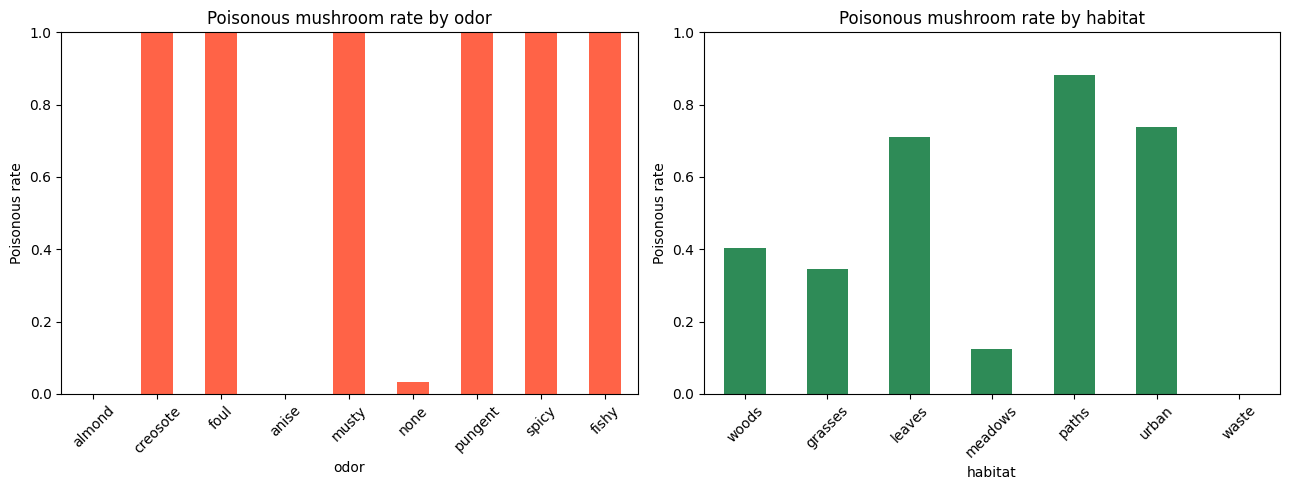

In [24]:
# Convert the class label to a numeric indicator so its mean is the poison rate.
plot_df = df.assign(is_poisonous=df["class"].eq("p").astype(int))

odor_names = {
    "a": "almond", "c": "creosote", "f": "foul",
    "l": "anise", "m": "musty", "n": "none",
    "p": "pungent", "s": "spicy", "y": "fishy",
}
habitat_names = {
    "d": "woods", "g": "grasses", "l": "leaves",
    "m": "meadows", "p": "paths", "u": "urban", "w": "waste",
}

poison_by_odor = plot_df.groupby("odor")["is_poisonous"].mean()
poison_by_odor.index = poison_by_odor.index.map(odor_names)
poison_by_habitat = plot_df.groupby("habitat")["is_poisonous"].mean()
poison_by_habitat.index = poison_by_habitat.index.map(habitat_names)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
poison_by_odor.plot.bar(
    ax=axes[0], title="Poisonous mushroom rate by odor", color="tomato"
)
poison_by_habitat.plot.bar(
    ax=axes[1], title="Poisonous mushroom rate by habitat", color="seagreen"
)

for ax in axes:
    ax.set_ylabel("Poisonous rate")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [25]:
TARGET = "class"
FEATURES = [column for column in df.columns if column != TARGET]

X, y = df[FEATURES], df[TARGET]

# Stratified split: 80% training and 20% test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Train: {len(X_train):,} rows ({len(X_train) / len(df):.1%})")
print(f"Test:  {len(X_test):,} rows ({len(X_test) / len(df):.1%})")
print(
    "Poisonous rate: "
    f"train {y_train.eq('p').mean():.1%}, "
    f"test {y_test.eq('p').mean():.1%}"
)

Train: 6,499 rows (80.0%)
Test:  1,625 rows (20.0%)
Poisonous rate: train 48.2%, test 48.2%


In [26]:
# Baseline: always predict the most common training class.
majority_class = y_train.mode().iloc[0]
baseline_predictions = pd.Series(
    majority_class, index=y_test.index, name="prediction"
)
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

class_names = {"e": "edible", "p": "poisonous"}
print(f"Baseline prediction: always {class_names[majority_class]} ({majority_class})")
print(f"Baseline test accuracy: {baseline_accuracy:.1%}")
print(f"Accuracy to beat: > {baseline_accuracy:.1%}")

Baseline prediction: always edible (e)
Baseline test accuracy: 51.8%
Accuracy to beat: > 51.8%


## 4. Compare five models with 5-fold cross-validation

The mushroom target is close to balanced (about 48% poisonous), so the accuracy paradox is less severe than in the churn example. However, **poisonous recall** is especially important: a false edible prediction could be dangerous. We therefore compare accuracy, precision, recall, F1, and ROC AUC.

All mushroom predictors are categorical, so each pipeline first uses one-hot encoding. Cross-validation uses only the training set; the test set remains untouched until final evaluation.

In [27]:
# Use 1 for poisonous and 0 for edible so metric direction is explicit.
y_train_binary = y_train.eq("p").astype(int)

RANDOM_STATE = 42

def build_model_pipeline(estimator, scale=False):
    """Create a reusable pipeline for categorical mushroom features."""
    steps = [("encoder", OneHotEncoder(handle_unknown="ignore"))]
    if scale:
        steps.append(("scaler", StandardScaler(with_mean=False)))
    steps.append(("model", estimator))
    return Pipeline(steps)

candidates = {
    "logistic regression": build_model_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=1000), scale=True
    ),
    "decision tree": build_model_pipeline(
        DecisionTreeClassifier(
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
    ),
    "random forest": build_model_pipeline(
        RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    ),
    "extra trees": build_model_pipeline(
        ExtraTreesClassifier(
            n_estimators=300,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    ),
    "support vector machine": build_model_pipeline(
        CalibratedClassifierCV(
            SVC(kernel="rbf", class_weight="balanced", C=1.0),
            method="sigmoid",
            cv=3,
            ensemble=False,
        ),
        scale=True,
    ),
}

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC AUC": "roc_auc",
}

rows = []
for name, candidate in candidates.items():
    cv_scores = cross_validate(
        candidate, X_train, y_train_binary, cv=folds, scoring=scoring, n_jobs=-1
    )
    row = {"Model": name}
    for metric in scoring:
        values = cv_scores[f"test_{metric}"]
        row[metric] = values.mean()
        row[f"{metric} std"] = values.std()
    rows.append(row)
    print(
        f"{name:<23} ROC AUC {row['ROC AUC']:.3f} "
        f"(+/- {row['ROC AUC std']:.3f}), recall {row['Recall']:.3f}"
    )

comparison = (
    pd.DataFrame(rows)
    .set_index("Model")
    .sort_values(["ROC AUC", "Recall"], ascending=False)
)
best_name = comparison.index[0]
model = candidates[best_name]
print(f"\nBest cross-validated model: {best_name}")
comparison.round(3)

logistic regression     ROC AUC 1.000 (+/- 0.000), recall 0.999
decision tree           ROC AUC 1.000 (+/- 0.000), recall 0.999
random forest           ROC AUC 1.000 (+/- 0.000), recall 0.999
extra trees             ROC AUC 1.000 (+/- 0.000), recall 0.999
support vector machine  ROC AUC 1.000 (+/- 0.001), recall 0.999

Best cross-validated model: decision tree


,Accuracy,Accuracy std,Precision,Precision std,Recall,Recall std,F1,F1 std,ROC AUC,ROC AUC std
Model,,,,,,,,,,
decision tree,0.999,0.001,1.0,0.0,0.999,0.003,0.999,0.001,1.0,0.000
random forest,0.999,0.001,1.0,0.0,0.999,0.003,0.999,0.001,1.0,0.000
extra trees,0.999,0.001,1.0,0.0,0.999,0.003,0.999,0.001,1.0,0.000
logistic regression,1.000,0.001,1.0,0.0,0.999,0.001,1.000,0.001,1.0,0.000
support vector machine,1.000,0.001,1.0,0.0,0.999,0.002,1.000,0.001,1.0,0.001


## 5. Choose the decision threshold

The selected model outputs the probability that a mushroom is poisonous. A threshold of 0.5 is only a default, so we choose the threshold that gives the best F1 score.

The probabilities below are out-of-fold predictions from the training data: every mushroom is scored by a model that was not trained on that row. The test set remains untouched, keeping the final test result honest.

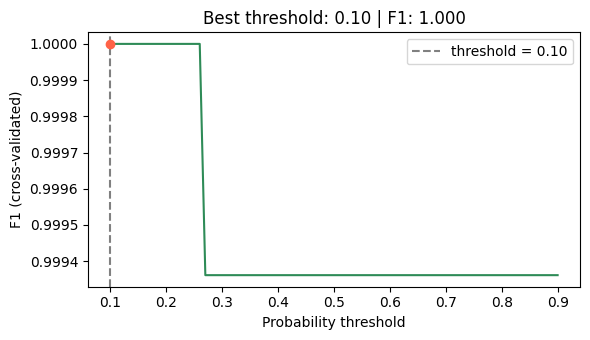

Selected threshold: 0.10
Cross-validated F1: 1.000


In [28]:
# Generate out-of-fold probabilities using only the training data.
proba_cv = cross_val_predict(
    model,
    X_train,
    y_train_binary,
    cv=folds,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.01)
f1s = np.array([f1_score(y_train_binary, proba_cv >= t) for t in thresholds])
best_index = int(np.argmax(f1s))
threshold = float(np.round(thresholds[best_index], 2))
best_cv_f1 = float(f1s[best_index])

plt.figure(figsize=(6, 3.5))
plt.plot(thresholds, f1s, color="seagreen")
plt.axvline(
    threshold, linestyle="--", color="grey", label=f"threshold = {threshold:.2f}"
)
plt.scatter(threshold, best_cv_f1, color="tomato", zorder=3)
plt.xlabel("Probability threshold")
plt.ylabel("F1 (cross-validated)")
plt.title(f"Best threshold: {threshold:.2f} | F1: {best_cv_f1:.3f}")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Selected threshold: {threshold:.2f}")
print(f"Cross-validated F1: {best_cv_f1:.3f}")

## 6. Train on all training data and evaluate once on the test set

Now fit the chosen pipeline on all 80% of the training data and evaluate it once on the locked 20% test set. Here, `1` means poisonous and `0` means edible.

In [29]:
y_test_binary = y_test.eq("p").astype(int)

model.fit(X_train, y_train_binary)
test_proba = model.predict_proba(X_test)[:, 1]
test_predicted = (test_proba >= threshold).astype(int)

test_metrics = pd.Series(
    {
        "ROC AUC": roc_auc_score(y_test_binary, test_proba),
        "Accuracy": accuracy_score(y_test_binary, test_predicted),
        "Precision (poisonous)": precision_score(
            y_test_binary, test_predicted
        ),
        "Recall (poisonous)": recall_score(y_test_binary, test_predicted),
        "F1 (poisonous)": f1_score(y_test_binary, test_predicted),
    },
    name="Test score",
)
test_metrics.round(3)

ROC AUC                  1.000
Accuracy                 0.999
Precision (poisonous)    0.999
Recall (poisonous)       1.000
F1 (poisonous)           0.999
Name: Test score, dtype: float64

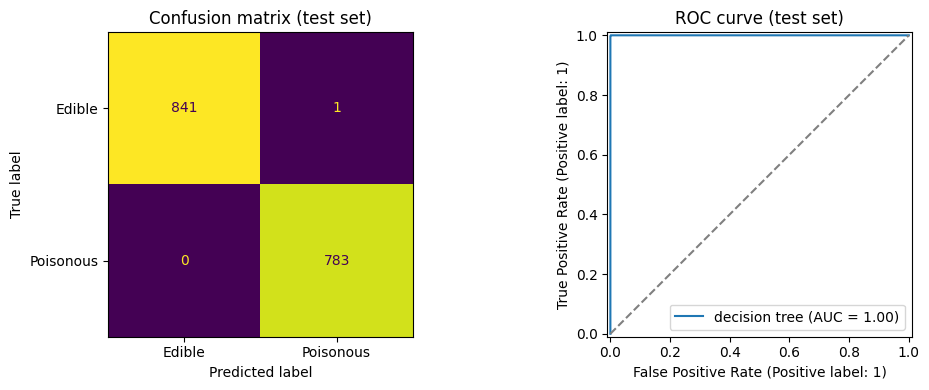

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    test_predicted,
    display_labels=["Edible", "Poisonous"],
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title("Confusion matrix (test set)")

RocCurveDisplay.from_predictions(
    y_test_binary, test_proba, ax=axes[1], name=best_name
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[1].set_title("ROC curve (test set)")
plt.tight_layout()
plt.show()

Read the confusion matrix with safety in mind: the bottom-right cell contains poisonous mushrooms correctly detected; the bottom-left contains poisonous mushrooms incorrectly called edible, the most dangerous error. The top-right contains edible mushrooms conservatively flagged as poisonous.

## 7. Which mushroom features matter?

**Permutation importance** shuffles one original feature at a time and measures the decrease in ROC AUC. A larger decrease means that the fitted pipeline relies more strongly on that mushroom characteristic.

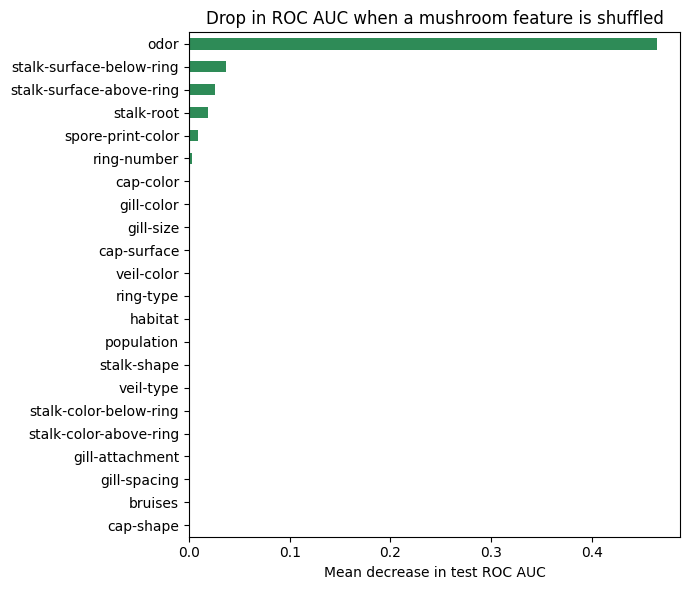

In [31]:
importance = permutation_importance(
    model,
    X_test,
    y_test_binary,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance_scores = pd.Series(
    importance.importances_mean, index=FEATURES, name="ROC AUC decrease"
).sort_values()

ax = importance_scores.plot.barh(
    figsize=(7, 6),
    color="seagreen",
    title="Drop in ROC AUC when a mushroom feature is shuffled",
)
ax.set_xlabel("Mean decrease in test ROC AUC")
plt.tight_layout()
plt.show()

## 8. Predict a new mushroom

The pipeline expects the same 22 feature columns in a DataFrame. The example below represents one mushroom using the dataset's category codes, predicts its poison probability, and applies the selected threshold. The helper can also be reused by an API after converting incoming JSON to a DataFrame.

> A machine-learning prediction is not a guarantee that a wild mushroom is safe to eat.

In [32]:
def predict_mushrooms(mushrooms, fitted_model=model, cutoff=threshold):
    """Return poison probabilities and threshold-based labels."""
    missing = set(FEATURES) - set(mushrooms.columns)
    if missing:
        raise ValueError(f"Missing features: {sorted(missing)}")

    probabilities = fitted_model.predict_proba(mushrooms[FEATURES])[:, 1]
    predictions = np.where(probabilities >= cutoff, "poisonous", "edible")
    return pd.DataFrame(
        {
            "poisonous_probability": probabilities,
            "prediction": predictions,
        },
        index=mushrooms.index,
    )

new_mushroom = pd.DataFrame(
    [
        {
            "cap-shape": "x",
            "cap-surface": "s",
            "cap-color": "n",
            "bruises": "t",
            "odor": "p",
            "gill-attachment": "f",
            "gill-spacing": "c",
            "gill-size": "n",
            "gill-color": "k",
            "stalk-shape": "e",
            "stalk-root": "e",
            "stalk-surface-above-ring": "s",
            "stalk-surface-below-ring": "s",
            "stalk-color-above-ring": "w",
            "stalk-color-below-ring": "w",
            "veil-type": "p",
            "veil-color": "w",
            "ring-number": "o",
            "ring-type": "p",
            "spore-print-color": "k",
            "population": "s",
            "habitat": "u",
        }
    ]
)
predict_mushrooms(new_mushroom).round(3)

,poisonous_probability,prediction
0,1.0,poisonous


In [33]:
# Change only odor to see how the fitted model reacts.
odor_scenarios = pd.concat(
    [new_mushroom.assign(odor=code) for code in odor_names], ignore_index=True
)
odor_scenarios.index = [odor_names[code] for code in odor_names]
odor_scenarios.index.name = "odor"
predict_mushrooms(odor_scenarios).sort_values(
    "poisonous_probability", ascending=False
).round(3)

,poisonous_probability,prediction
odor,,
creosote,1.0,poisonous
fishy,1.0,poisonous
foul,1.0,poisonous
musty,1.0,poisonous
pungent,1.0,poisonous
spicy,1.0,poisonous
almond,0.0,edible
anise,0.0,edible
none,0.0,edible


## 9. Save the model for the API

Save the fitted preprocessing-and-classification pipeline together with everything the API needs: the algorithm name, expected feature order, target labels, decision threshold, final test metrics, training timestamp, and scikit-learn version.

In [37]:
MODEL_PATH = Path("../models/mushroom.joblib")
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

bundle = {
    "model": model,
    "algorithm": best_name,
    "features": FEATURES,
    "target": TARGET,
    "class_labels": {0: "edible", 1: "poisonous"},
    "threshold": threshold,
    "metrics": {
        name: round(float(value), 4) for name, value in test_metrics.items()
    },
    "trained_at": pd.Timestamp.now(tz="UTC").isoformat(
        timespec="seconds"
    ),
    "sklearn_version": sklearn.__version__,
}

joblib.dump(bundle, MODEL_PATH)
print(f"Saved model bundle to: {MODEL_PATH.resolve()}")

Saved model bundle to: C:\Users\USER\Documents\Techpreneur Bootcamp\Data Science\Mushroom Classificaion\models\mushroom.joblib
